#### imports

In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import matplotlib.cm as cm
from IPython.display import display
import statsmodels.formula.api as smf


In [32]:
df = pd.read_csv("https://drive.google.com/uc?id=1GWHKPdxVuqroKoKoB49zOEyfyLAwbzcc", encoding="latin1")

In [ ]:
df[df['Sales']<1500]['Sales'].sort_values().hist(bins=1000)
# df[df['Sales']<1500]['Sales'].sort_values().hist(bins=100)
# df[df['Sales']<1500]['Sales'].sort_values().hist()
# df[df['Sales']<1500]['Sales'].sort_values().plot(kind='kde')

#### measures of location

In [39]:
scores = pd.Series([2,4,4,6,9])

# scores.sum()
# scores.mean()
# scores.median()
# scores.mode()
scores.max() - scores.min()

np.int64(7)

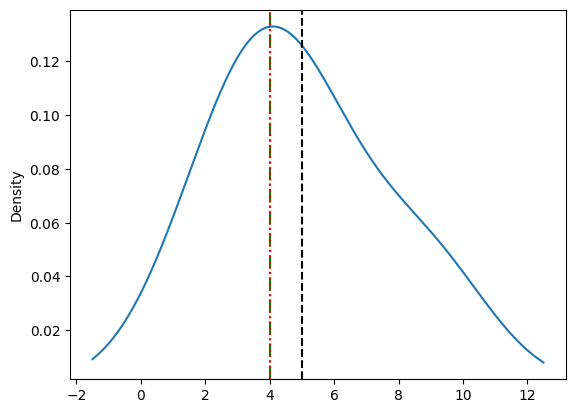

In [41]:
scores = pd.Series([2,4,4,6,9])
ax = scores.plot(kind='kde')
ax.axvline(scores.mean(), color='k', linestyle='--')
ax.axvline(scores.median(), color='g', linestyle='-.')
ax.axvline(scores.mode()[0], color='r', linestyle=':')

mean: -35.4  |  median: 4.0


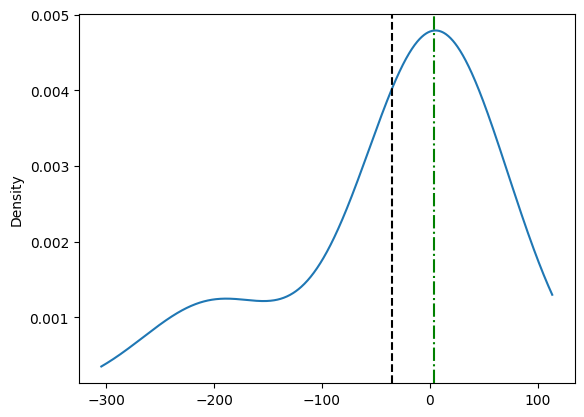

In [42]:
s2 = pd.Series([-200,4,4,6,9])
ax = s2.plot(kind='kde')
ax.axvline(s2.mean(), color='k', linestyle='--')
ax.axvline(s2.median(), color='g', linestyle='-.')
print("mean:", s2.mean() , " | ", "median:", s2.median())
plt.show()

#### Quantile & IQR

<Axes: >

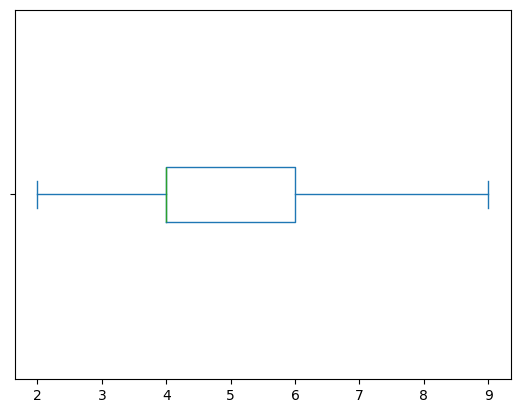

In [51]:
scores = pd.Series([2,4,4,6,9])
scores.quantile(1)
scores.plot(kind='box', vert=False)

#### variance

In [57]:
s3 = pd.Series([-2,4,4,6,90])

print("mean:", s3.mean().round(1))

var = sum((s3 - s3.mean())**2) / (s3.size-1)

var

s3.var()

np.sqrt(s3.var())

# s3.std()

mean: 20.4


np.float64(39.02307009962183)

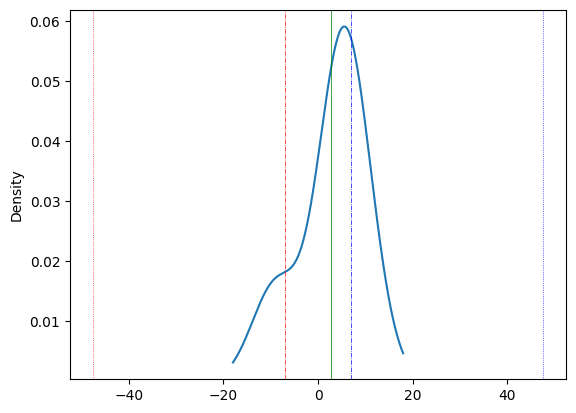

In [58]:
s4 = pd.Series([-9,4,4,6,9])
ax = s4.plot(kind='kde')

ax.axvline(-s4.var(), color='r', linestyle=':', linewidth=0.5)
ax.axvline(s4.var(), color='b', linestyle=':', linewidth=0.5)

ax.axvline(s4.mean(), color='g', linestyle='-', linewidth=0.5)

ax.axvline(-s4.std(), color='r', linestyle='-.', linewidth=0.5)
ax.axvline(s4.std(), color='b', linestyle='-.', linewidth=0.5)


#### skewness & kurtosis

<Axes: ylabel='Frequency'>

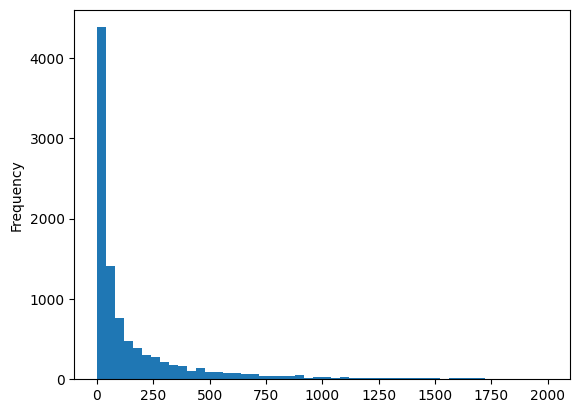

In [68]:
# df['Profit'].sort_values().plot(kind='hist', bins=100)
# df[(df.Profit>-100) & (df.Profit<100)]['Profit'].sort_values().plot(kind='hist', bins=50)

df[df.Sales<2000]['Sales'].sort_values().plot(kind='hist', bins=50)
# df[df.Sales<2000]['Sales'].plot(kind='kde')

# df[(df.Profit>-100) & (df.Profit<100)]['Profit'].sort_values().plot(kind='hist', bins=100)
# df[(df.Profit>-100) & (df.Profit<100)]['Profit'].sort_values().plot(kind='kde')


In [ ]:
df['Profit'].skew()                              # > 0 indicates right-skew
df['Profit'].kurtosis()

#### normal curve

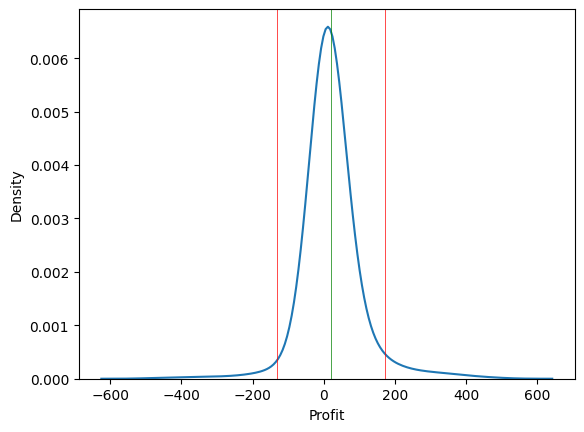

In [88]:
profits = df[(df.Profit>-500) & (df.Profit<500)]['Profit'].sort_values()

# ax = sns.histplot(profits)
ax = sns.kdeplot(profits, bw_adjust=4)

avg = profits.mean()
std = profits.std()
mode = profits.mode()[0]
ax.axvline((avg -2*std), color='r', linewidth=0.5)
ax.axvline((avg +2*std), color='r', linewidth=0.5)
# ax.axvline(mode, color='orange', linewidth=0.5)
ax.axvline(avg, color='g', linewidth=0.5)

In [ ]:
flu = pd.read_csv("../../../../../Data/AgesAtDeathSpanishFlu1918.csv")
sns.kdeplot(flu, bw_adjust=1)
sns.kdeplot(flu, bw_adjust=5)

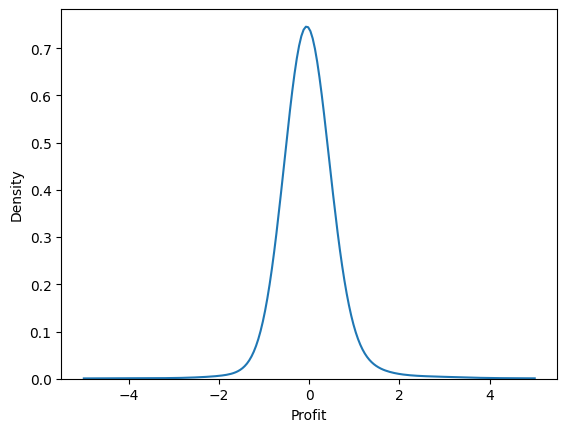

In [75]:
profits = df['Profit']

# mean and stadard deviation of profits
avg = profits.mean()
std = profits.std()

# calculate individual z-score
z = (profits - avg) / std

# plot z-scores
# sns.histplot(z)
ax = sns.kdeplot(z, bw_adjust=3, clip=(-5, 5))

# show emperical rule in term of deviation from 0 in terms of standard deviations
# ax.axvline(-1, color='r', linewidth=0.5)
# ax.axvline(+1, color='r', linewidth=0.5)
# ax.axvline(0, color='g', linewidth=0.5)

#### central limit theorem

In [ ]:
def demonstrate_clt(num_samples=1000, sample_size=30, scale=2.0):
    """
    Demonstrates the Central Limit Theorem.

    Parameters:
    - num_samples: Number of sample means to draw (default 1000)
    - sample_size: Size (n) of each individual sample
    - scale: Scale parameter for the exponential distribution
    """
    # 1. Generate Population Data (Non-Normal / Exponentially Skewed)
    np.random.seed(42)
    pop_size = 100_000
    population = np.random.exponential(scale=scale, size=pop_size)

    # 2. Draw 'num_samples' samples of size 'sample_size' and compute means
    samples = np.random.choice(population, size=(num_samples, sample_size))
    sample_means = samples.mean(axis=1)

    # 3. Plotting
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Left Plot: Original Skewed Population
    axes[0].hist(population, bins=60, density=True, color='crimson', alpha=0.7, edgecolor='black')
    axes[0].set_title(f"1. Original Population Distribution (Skewed)\nN = {pop_size:,}", fontweight='bold')
    axes[0].set_xlabel("Value (X)")
    axes[0].set_ylabel("Density")
    axes[0].grid(True, alpha=0.3)

    # Right Plot: Sampling Distribution of Sample Means
    axes[1].hist(sample_means, bins=35, density=True, color='royalblue', alpha=0.7, edgecolor='black')

    # Overlay Normal Fit Curve for comparison
    mean_of_means = np.mean(sample_means)
    std_of_means = np.std(sample_means, ddof=1)
    x_range = np.linspace(min(sample_means), max(sample_means), 200)
    axes[1].plot(x_range, stats.norm.pdf(x_range, mean_of_means, std_of_means),
                 'k--', lw=2.5, label=f'Normal Fit (μ={mean_of_means:.2f}, SE={std_of_means:.2f})')

    axes[1].set_title(f"2. Sampling Distribution of the Mean\n{num_samples:,} Samples of size n = {sample_size}", fontweight='bold')
    axes[1].set_xlabel("Sample Mean (x̄)")
    axes[1].set_ylabel("Density")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    display(fig)
    plt.close(fig)

demonstrate_clt(num_samples=2000, sample_size=300)

#### t-distribution

In [ ]:
df_list = [1, 30]

def analyze_t_distribution(df_list):
    """
    Visualizes t-distribution PDF convergence and critical value penalties,
    and prints a summary table for any custom list of degrees of freedom.
    """
    colors = cm.plasma(np.linspace(0.1, 0.9, len(df_list)))

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    # ------------------------------------------------------------------
    # PLOT 1: Probability Density Functions
    # ------------------------------------------------------------------
    x = np.linspace(-4, 4, 1000)
    axes[0].plot(x, stats.norm.pdf(x), 'k--', lw=1.5, label='Normal (Z) [df = ∞]', zorder=10)

    for df_val, color in zip(df_list, colors):
        axes[0].plot(x, stats.t.pdf(x, df=df_val), label=f't (df = {df_val})', color=color, lw=1.8)

    axes[0].set_title("1. Shape Convergence to Normal (Z)", fontsize=12, fontweight='bold')
    axes[0].set_xlabel("t-value (Standard Errors from Mean)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend(loc='upper right', fontsize=9)
    axes[0].grid(True, alpha=0.3)

    # ------------------------------------------------------------------
    # PLOT 2: Critical Value Penalty Curve
    # ------------------------------------------------------------------
    alpha = 0.05
    z_crit = stats.norm.ppf(1 - alpha/2)

    max_df_plot = max([d for d in df_list if d <= 50], default=30)
    dfs_smooth = np.linspace(1, max(max_df_plot, 30), 200)
    t_crits_smooth = stats.t.ppf(1 - alpha/2, df=dfs_smooth)

    axes[1].plot(dfs_smooth, t_crits_smooth, color='gray', linestyle='-', alpha=0.7, zorder=1)
    axes[1].axhline(z_crit, color='k', linestyle='--', label=f'Z Critical Value ({z_crit:.3f})', zorder=2)

    for d_val, color in zip(df_list, colors):
        t_c = stats.t.ppf(1 - alpha/2, df=d_val)
        axes[1].scatter(d_val, t_c, color=color, s=70, zorder=5, label=f'df = {d_val} (t* = {t_c:.2f})')

    axes[1].set_title("2. Critical Value Penalty (α = 0.05, Two-Tailed)", fontsize=12, fontweight='bold')
    axes[1].set_xlabel("Degrees of Freedom (df)")
    axes[1].set_ylabel("Critical Value (t*)")
    axes[1].set_xlim(0, max(max_df_plot, 30) + 2)
    axes[1].set_ylim(1.5, 4.5)
    axes[1].legend(loc='upper right', fontsize=9)
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()

    # Force output display inside Jupyter environment
    display(fig)
    plt.close(fig)

    # ------------------------------------------------------------------
    # PRINTED TABLE: Fully Aligned with Figures
    # ------------------------------------------------------------------
    print(f"{'Distribution / df':<20} | {'Critical t* (α=0.05)':<22} | {'Tail Prob P(X > 2.5 SE)':<25}")
    print("-" * 72)

    for df_val in df_list:
        t_crit = stats.t.ppf(0.975, df=df_val)
        tail_prob = 1 - stats.t.cdf(2.5, df=df_val)
        print(f"t-dist (df = {df_val:<4})     | {t_crit:<22.4f} | {tail_prob:<25.4%}")

    z_crit_val = stats.norm.ppf(0.975)
    z_tail_prob = 1 - stats.norm.cdf(2.5)
    print("-" * 72)
    print(f"{'Standard Normal (Z)':<20} | {z_crit_val:<22.4f} | {z_tail_prob:<25.4%}")

analyze_t_distribution(df_list)

#### confidence interval

In [ ]:
def demonstrate_se_ci(sample_sizes=[10, 30, 100, 500], confidence=0.95, true_mean=100.0, true_std=15.0):
    """
    Demonstrates how sample size (n) affects the Standard Error (SE) and 95% Confidence Interval width.

    Parameters:
    - sample_sizes: List of 4 sample sizes (n) to compare
    - confidence: Confidence level (default 0.95)
    - true_mean: Known population mean (μ)
    - true_std: Known population standard deviation (σ)
    """
    if len(sample_sizes) != 4:
        raise ValueError("Please provide exactly 4 sample sizes in a list.")

    z_crit = stats.norm.ppf(1 - (1 - confidence) / 2)
    fig, axes = plt.subplots(4, 1, figsize=(12, 6), sharex=True)

    colors = ['crimson', 'orange', 'mediumseagreen', 'royalblue']

    for i, (n, color) in enumerate(zip(sample_sizes, colors)):
        ax = axes[i]

        # Calculate Standard Error and Margin of Error
        se = true_std / np.sqrt(n)
        margin_of_error = z_crit * se
        ci_lower = true_mean - margin_of_error
        ci_upper = true_mean + margin_of_error

        # Plot True Mean baseline
        ax.axvline(true_mean, color='black', linestyle='--', alpha=0.7, zorder=1)

        # Plot Confidence Interval bar & endpoints
        ax.errorbar(true_mean, 0, xerr=margin_of_error, fmt='o', color=color,
                    ecolor=color, elinewidth=3, capsize=8, capthick=2, zorder=3,
                    label=f"n = {n:<4} | SE = {se:.2f} | 95% CI: [{ci_lower:.2f}, {ci_upper:.2f}]")

        ax.set_yticks([])
        ax.set_ylabel(f"n = {n}", rotation=0, labelpad=25, fontweight='bold', fontsize=11)
        ax.legend(loc='upper right', fontsize=10)
        ax.grid(True, alpha=0.3, axis='x')

    # Formatting outer shared elements
    axes[0].set_title(f"Impact of Sample Size (n) on 95% Confidence Interval Width\n(Population μ = {true_mean}, σ = {true_std})",
                      fontsize=12, fontweight='bold')
    axes[-1].set_xlabel("Value (Population Mean μ)", fontsize=11)
    axes[-1].set_xlim(true_mean - (true_std * 1.2), true_mean + (true_std * 1.2))

    plt.tight_layout()
    display(fig)
    plt.close(fig)

# Change the list of sample sizes to see how CIs change width dynamically
demonstrate_se_ci(sample_sizes=[10, 30, 100, 500])

#### regression line

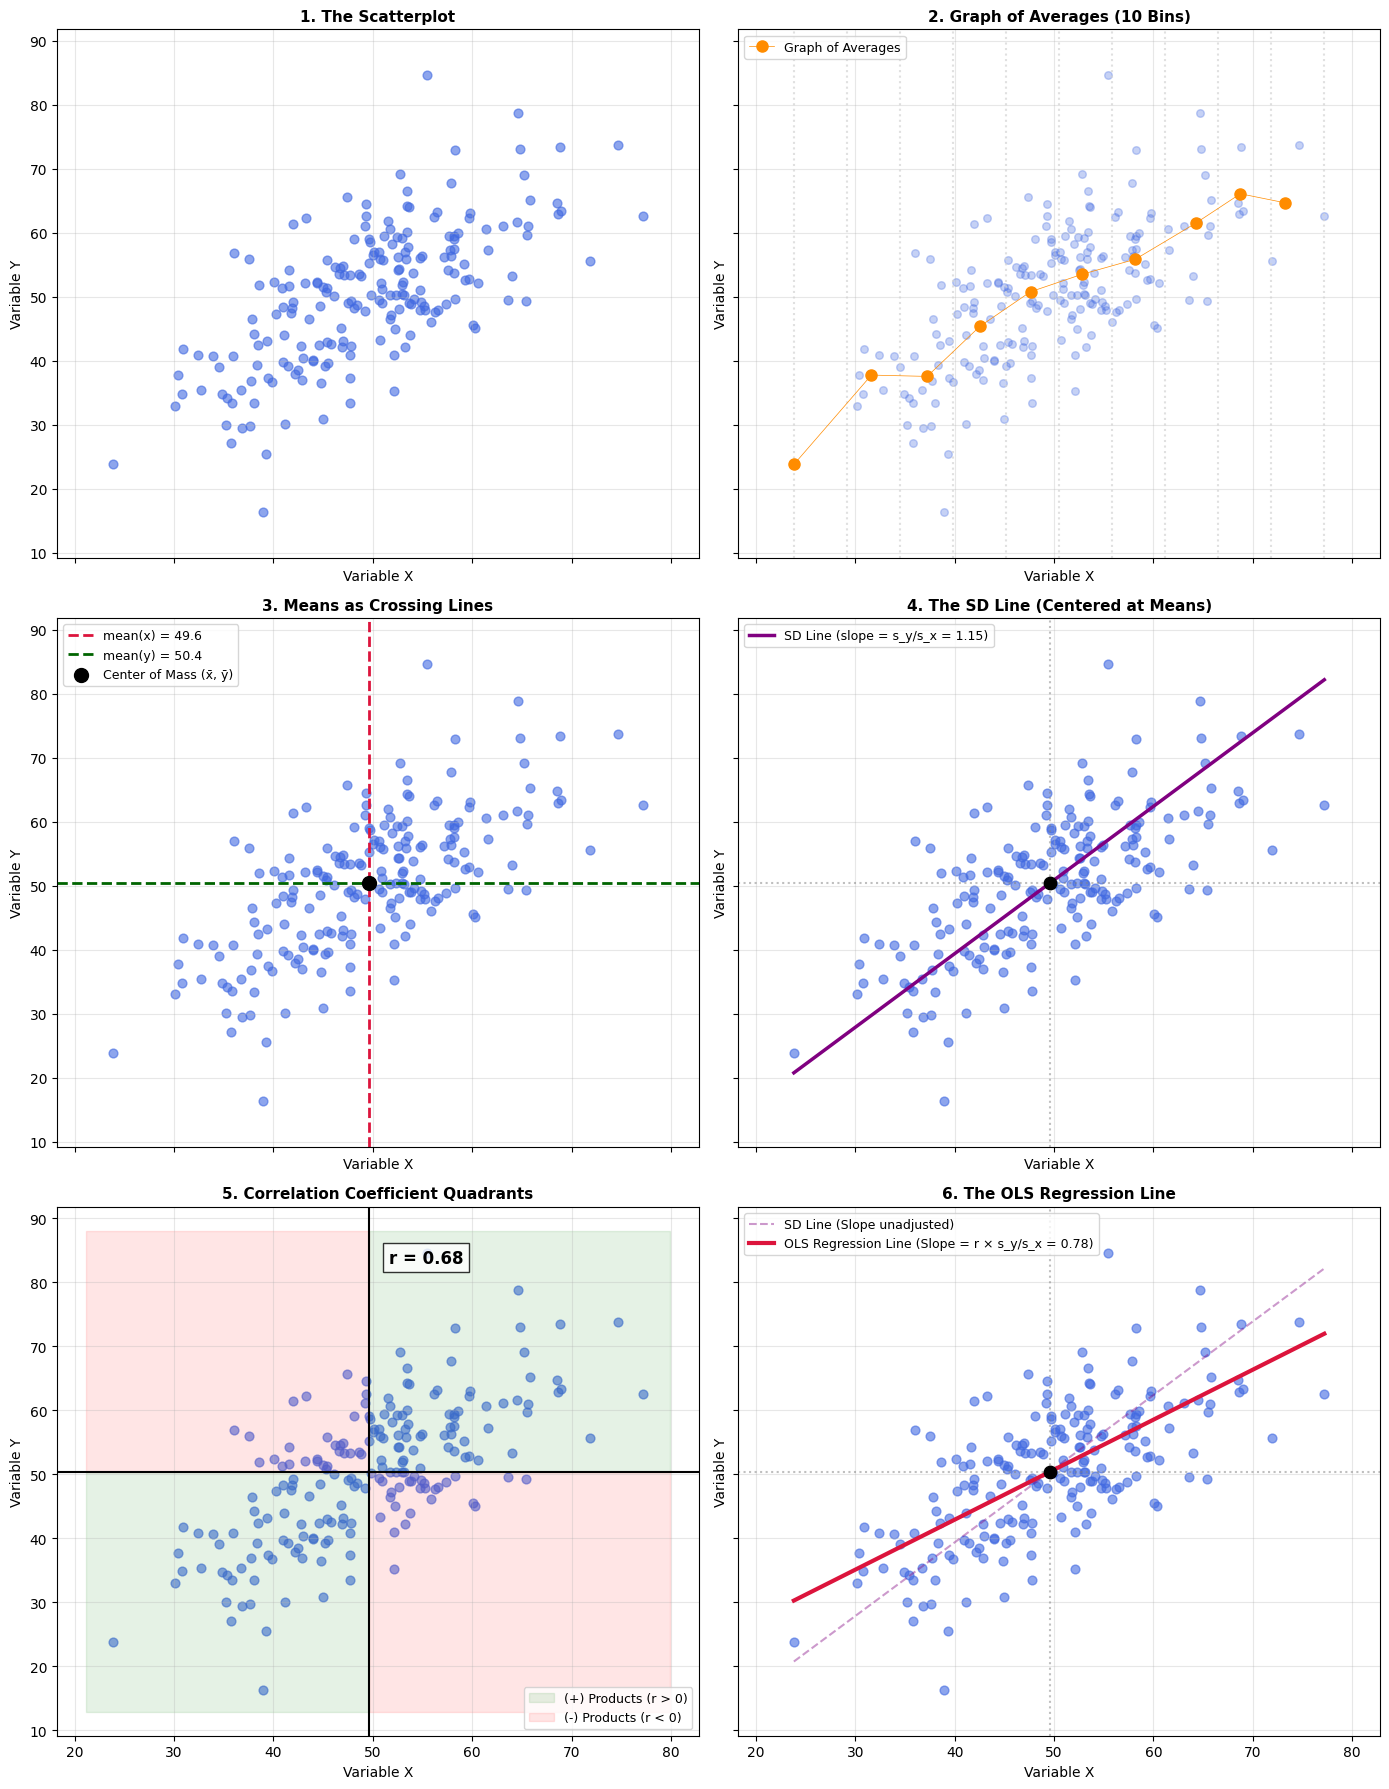

In [90]:
def demonstrate_regression_evolution(n=200, seed=42):
    """
    Generates a 6-panel figure showing the conceptual steps from a raw
    scatterplot to the final regression line, including the graph of averages,
    means, the SD line, and the correlation quadrants.
    """
    np.random.seed(seed)

    # 1. Generate correlated synthetic data
    x = np.random.normal(loc=50, scale=10, size=n)
    # y is correlated with x plus some error noise
    y = 0.7 * x + np.random.normal(loc=0, scale=8, size=n) + 15

    # Calculate statistics
    x_bar, y_bar = np.mean(x), np.mean(y)
    s_x, s_y = np.std(x, ddof=1), np.std(y, ddof=1)
    r = np.corrcoef(x, y)[0, 1]
    slope_ols = r * (s_y / s_x)
    intercept_ols = y_bar - slope_ols * x_bar
    slope_sd = s_y / s_x  # SD line slope

    # Set up 3x2 grid of subplots
    fig, axes = plt.subplots(3, 2, figsize=(14, 18), sharex=True, sharey=True)
    axes = axes.flatten()

    # ------------------------------------------------------------------
    # Panel 1: The Raw Scatterplot
    # ------------------------------------------------------------------
    axes[0].scatter(x, y, alpha=0.6, color='royalblue', s=40)
    axes[0].set_title("1. The Scatterplot", fontweight='bold', fontsize=11)

    # ------------------------------------------------------------------
    # Panel 2: The Graph of Averages (10 Bins)
    # ------------------------------------------------------------------
    axes[1].scatter(x, y, alpha=0.3, color='royalblue', s=30)

    # Bin x into 10 equal-width stripes / quantiles
    bin_edges = np.linspace(min(x), max(x), 11)
    bin_indices = np.digitize(x, bin_edges) - 1

    bin_means_x, bin_means_y = [], []
    for i in range(10):
        mask = (bin_indices == i)
        if np.any(mask):
            bin_means_x.append(np.mean(x[mask]))
            bin_means_y.append(np.mean(y[mask]))

    # Draw vertical stripe boundaries
    for edge in bin_edges:
        axes[1].axvline(edge, color='lightgray', linestyle=':', alpha=0.7)

    axes[1].plot(bin_means_x, bin_means_y, 'o-', color='darkorange', lw=0.5, markersize=8,
                 label='Graph of Averages')
    axes[1].set_title("2. Graph of Averages (10 Bins)", fontweight='bold', fontsize=11)
    axes[1].legend(loc='upper left', fontsize=9)

    # ------------------------------------------------------------------
    # Panel 3: Scatterplot + Mean of X and Mean of Y
    # ------------------------------------------------------------------
    axes[2].scatter(x, y, alpha=0.6, color='royalblue', s=40)
    axes[2].axvline(x_bar, color='crimson', linestyle='--', lw=2, label=f'mean(x) = {x_bar:.1f}')
    axes[2].axhline(y_bar, color='darkgreen', linestyle='--', lw=2, label=f'mean(y) = {y_bar:.1f}')
    axes[2].scatter([x_bar], [y_bar], color='black', s=100, zorder=5, label='Center of Mass (x̄, ȳ)')

    axes[2].set_title("3. Means as Crossing Lines", fontweight='bold', fontsize=11)
    axes[2].legend(loc='upper left', fontsize=9)

    # ------------------------------------------------------------------
    # Panel 4: Scatterplot + The SD Line
    # ------------------------------------------------------------------
    axes[3].scatter(x, y, alpha=0.6, color='royalblue', s=40)
    axes[3].axvline(x_bar, color='gray', linestyle=':', alpha=0.5)
    axes[3].axhline(y_bar, color='gray', linestyle=':', alpha=0.5)

    # SD line passes through (x_bar, y_bar) with slope s_y / s_x
    x_line = np.linspace(min(x), max(x), 100)
    y_sd_line = y_bar + slope_sd * (x_line - x_bar)
    axes[3].plot(x_line, y_sd_line, color='purple', lw=2.5, label=f'SD Line (slope = s_y/s_x = {slope_sd:.2f})')
    axes[3].scatter([x_bar], [y_bar], color='black', s=80, zorder=5)

    axes[3].set_title("4. The SD Line (Centered at Means)", fontweight='bold', fontsize=11)
    axes[3].legend(loc='upper left', fontsize=9)

    # ------------------------------------------------------------------
    # Panel 5: Correlation Quadrants (+ / - regions)
    # ------------------------------------------------------------------
    axes[4].scatter(x, y, alpha=0.6, color='royalblue', s=40)
    axes[4].axvline(x_bar, color='black', linestyle='-', lw=1.5)
    axes[4].axhline(y_bar, color='black', linestyle='-', lw=1.5)

    # Shade quadrants based on sign of standard score products (r components)
    x_min, x_max = axes[4].get_xlim()
    y_min, y_max = axes[4].get_ylim()

    axes[4].fill_between([x_bar, x_max], y_bar, y_max, color='green', alpha=0.1, label='(+) Products (r > 0)')
    axes[4].fill_between([x_min, x_bar], y_min, y_bar, color='green', alpha=0.1)
    axes[4].fill_between([x_min, x_bar], y_bar, y_max, color='red', alpha=0.1, label='(-) Products (r < 0)')
    axes[4].fill_between([x_bar, x_max], y_min, y_bar, color='red', alpha=0.1)

    axes[4].text(x_bar + 2, y_max - 5, f'r = {r:.2f}', fontsize=12, fontweight='bold',
                 bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))
    axes[4].set_title("5. Correlation Coefficient Quadrants", fontweight='bold', fontsize=11)
    axes[4].legend(loc='lower right', fontsize=9)

    # ------------------------------------------------------------------
    # Panel 6: The OLS Regression Line (Flattened by r)
    # ------------------------------------------------------------------
    axes[5].scatter(x, y, alpha=0.6, color='royalblue', s=40)
    axes[5].axvline(x_bar, color='gray', linestyle=':', alpha=0.5)
    axes[5].axhline(y_bar, color='gray', linestyle=':', alpha=0.5)

    # Plot SD line faintly for comparison
    axes[5].plot(x_line, y_sd_line, color='purple', linestyle='--', alpha=0.4, label='SD Line (Slope unadjusted)')

    # Plot OLS Regression Line (Slope = r * s_y / s_x)
    y_ols_line = intercept_ols + slope_ols * x_line
    axes[5].plot(x_line, y_ols_line, color='crimson', lw=3, label=f'OLS Regression Line (Slope = r × s_y/s_x = {slope_ols:.2f})')
    axes[5].scatter([x_bar], [y_bar], color='black', s=80, zorder=5)

    axes[5].set_title("6. The OLS Regression Line", fontweight='bold', fontsize=11)
    axes[5].legend(loc='upper left', fontsize=9)

    # Apply shared labels across grid
    for ax in axes:
        ax.set_xlabel("Variable X", fontsize=10)
        ax.set_ylabel("Variable Y", fontsize=10)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    display(fig)
    plt.close(fig)

demonstrate_regression_evolution()

In [ ]:

# Generate some synthetic data for regression
np.random.seed(42)
x = np.linspace(0, 10, 50)
y = 2 * x + 1 + np.random.normal(0, 2, 50) # True relationship + noise

df = pd.DataFrame({'x': x, 'y': y})

# Fit a linear regression model
model = smf.ols("y ~ x", data=df).fit()

# Get predictions and their confidence intervals
predictions = model.get_prediction(df['x'])
pred_df = predictions.summary_frame(alpha=0.05) # 95% CI

plt.figure(figsize=(10, 7))
plt.scatter(df['x'], df['y'], alpha=0.6, label="Observed Data")

# Plot the regression line
plt.plot(df['x'], pred_df['mean'], color="red", label="Regression Line")

# Plot the confidence interval as a shaded region
plt.fill_between(
 df['x'],
 pred_df['obs_ci_lower'],
 pred_df['obs_ci_upper'],
 color="red",
 alpha=0.1,
 label="95% Prediction Interval"
)

# You can also plot the confidence interval for the mean prediction (narrower)
plt.fill_between(
 df['x'],
 pred_df['mean_ci_lower'],
 pred_df['mean_ci_upper'],
 color="blue",
 alpha=0.2,
 label="95% Mean Confidence Interval"
)

plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Linear Regression with Confidence and Prediction Intervals")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()